In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

You should consider upgrading via the '/Users/wchae/Developer/Courseworks/26 Fall/DSO607/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# **Problem 1**

## **(a)**

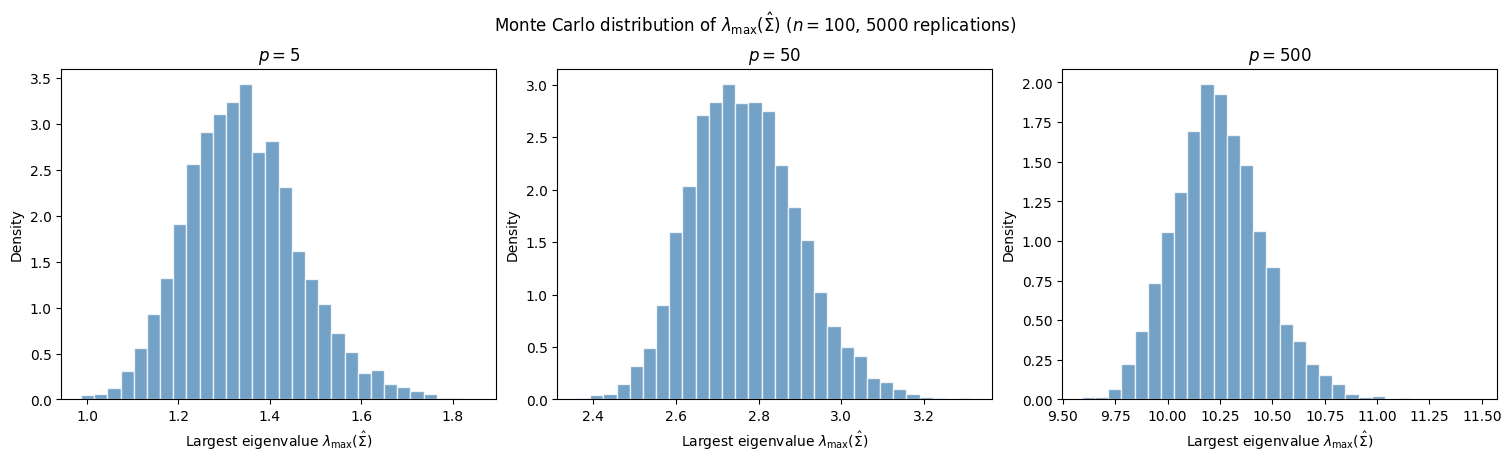

,Mean,Standard deviation,Median,5th percentile,95th percentile
p,,,,,
5,1.3418,0.1237,1.3345,1.1515,1.5581
50,2.7684,0.1300,2.7627,2.5714,2.9931
500,10.2438,0.2130,10.2333,9.9113,10.6132


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n = 100
p_values = [5, 50, 500]
n_replications = 5000
rng = np.random.default_rng(607)

def sample_largest_eigenvalues(p, n=n, n_replications=n_replications, rng=rng):
    if n <= 0:
        raise ValueError("n must be greater than 0")

    largest_eigenvalues = np.empty(n_replications)
    batch_size = 100

    for start in range(0, n_replications, batch_size):
        stop = min(start + batch_size, n_replications)
        x = rng.standard_normal((stop - start, n, p))
        singular_values = np.linalg.svd(x, compute_uv=False)
        largest_eigenvalues[start:stop] = singular_values[:, 0] ** 2 / n

    return largest_eigenvalues

largest_eigenvalues = {
    p: sample_largest_eigenvalues(p)
    for p in p_values
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, p in zip(axes, p_values):
    values = largest_eigenvalues[p]

    ax.hist(values, bins=30, density=True, alpha=0.75,
            color="steelblue", edgecolor="white")
    ax.set_title(fr"$p={p}$")
    ax.set_xlabel(r"Largest eigenvalue $\lambda_{\max}(\hat{\Sigma})$")
    ax.set_ylabel("Density")

fig.suptitle(
    fr"Monte Carlo distribution of $\lambda_{{\max}}(\hat{{\Sigma}})$ "
    fr"($n={n}$, {n_replications} replications)"
)
plt.show()

summary_table = pd.DataFrame({
    "p": p_values,
    "Mean": [largest_eigenvalues[p].mean() for p in p_values],
    "Standard deviation": [largest_eigenvalues[p].std(ddof=1) for p in p_values],
    "Median": [np.median(largest_eigenvalues[p]) for p in p_values],
    "5th percentile": [np.percentile(largest_eigenvalues[p], 5) for p in p_values],
    "95th percentile": [np.percentile(largest_eigenvalues[p], 95) for p in p_values],
}).set_index("p")

summary_table.round(4)

## **(b)**

The Marchenko--Pastur/Geman upper edge is

$$
\lambda_+(p/n) = (1 + \sqrt{p/n})^2.
$$

The fixed-dimensional benchmark is 1 because, for fixed $p$ and $n\to\infty$, the sample covariance converges to $I_p$. When $p/n$ is not small, high-dimensional noise shifts the largest eigenvalue upward to the upper edge $(1+\sqrt{p/n})^2$, so the benchmark 1 is misleading.

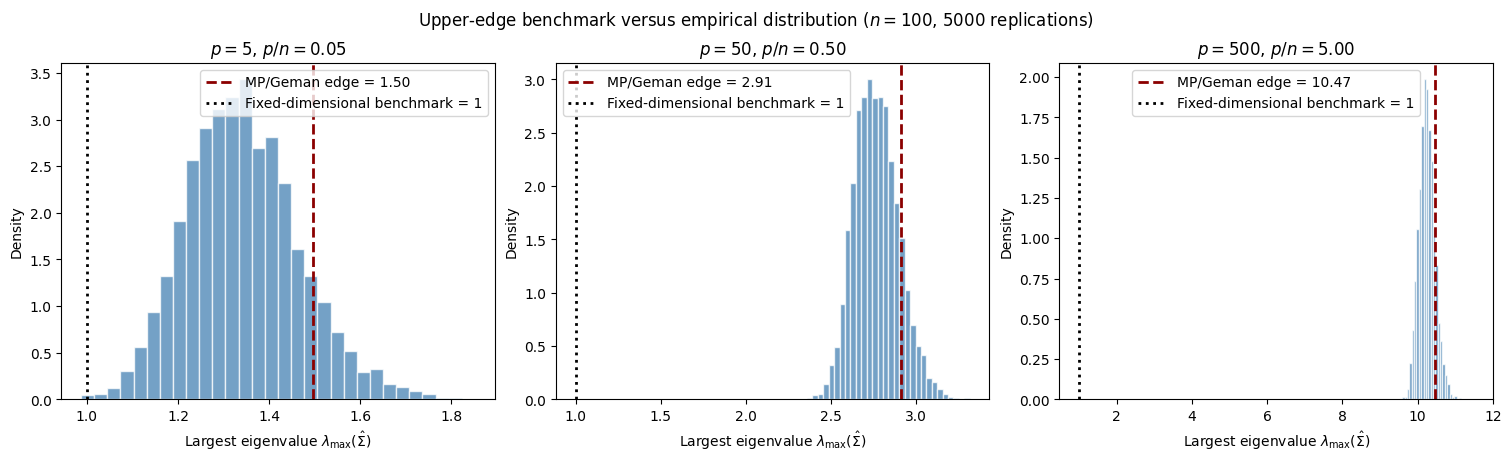

,p/n,MP/Geman upper edge,Empirical mean,Empirical 95th percentile
p,,,,
5,0.05,1.4972,1.3418,1.5581
50,0.50,2.9142,2.7684,2.9931
500,5.00,10.4721,10.2438,10.6132


In [3]:
import matplotlib.pyplot as plt

mp_edge_table = pd.DataFrame({
    "p": p_values,
    "p/n": [p / n for p in p_values],
    "MP/Geman upper edge": [
        (1 + np.sqrt(p / n)) ** 2
        for p in p_values
    ],
    "Empirical mean": [
        largest_eigenvalues[p].mean()
        for p in p_values
    ],
    "Empirical 95th percentile": [
        np.percentile(largest_eigenvalues[p], 95)
        for p in p_values
    ],
}).set_index("p")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, p in zip(axes, p_values):
    values = largest_eigenvalues[p]
    mp_edge = mp_edge_table.loc[p, "MP/Geman upper edge"]

    ax.hist(values, bins=30, density=True, alpha=0.75,
            color="steelblue", edgecolor="white")
    ax.axvline(mp_edge, color="darkred", linestyle="--", linewidth=2,
               label=fr"MP/Geman edge = {mp_edge:.2f}")
    ax.axvline(1, color="black", linestyle=":", linewidth=2,
               label="Fixed-dimensional benchmark = 1")
    ax.set_title(fr"$p={p}$, $p/n={p/n:.2f}$")
    ax.set_xlabel(r"Largest eigenvalue $\lambda_{\max}(\hat{\Sigma})$")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    fr"Upper-edge benchmark versus empirical distribution "
    fr"($n={n}$, {n_replications} replications)"
)
plt.show()

mp_edge_table.round(4)

## **(c)**

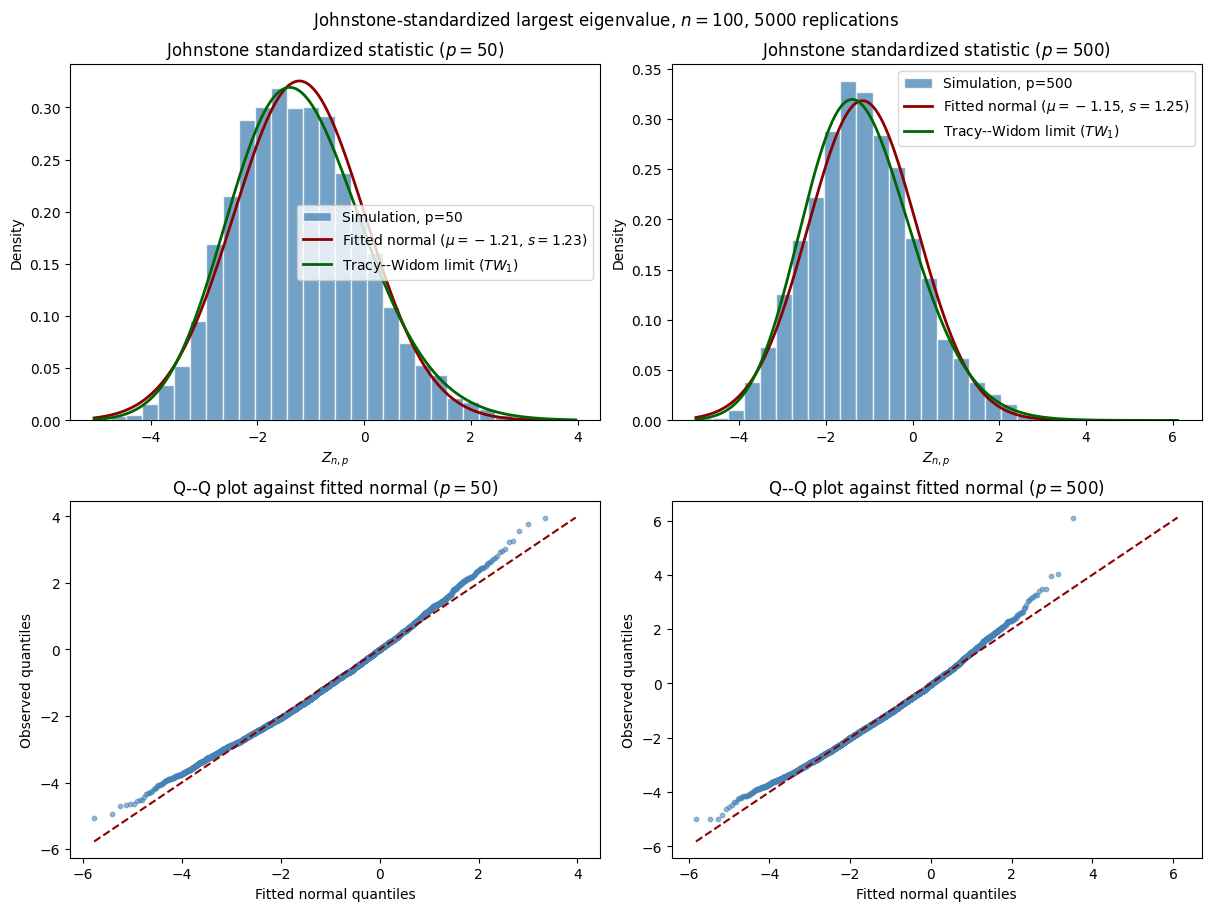

,Empirical mean,Empirical standard deviation,Empirical skewness
p,,,
50,-1.2139,1.2261,0.3253
500,-1.1537,1.2544,0.3374


In [4]:
from scipy.integrate import solve_ivp
from scipy.special import airy
from scipy.stats import norm, skew

johnstone_p_values = [50, 500]
standardized_eigenvalues = {}

for p in johnstone_p_values:
    mu_n_p = (np.sqrt(n - 1) + np.sqrt(p)) ** 2
    sigma_n_p = (np.sqrt(n - 1) + np.sqrt(p)) * (
        1 / np.sqrt(n - 1) + 1 / np.sqrt(p)
    ) ** (1 / 3)
    standardized_eigenvalues[p] = (
        n * largest_eigenvalues[p] - mu_n_p
    ) / sigma_n_p


def tracy_widom_beta_1_density(x_values):
    """Numerically evaluate the Tracy-Widom beta=1 density."""
    x_values = np.asarray(x_values, dtype=float)
    x_min = min(-8.0, x_values.min())
    x_max = max(8.0, x_values.max())
    airy_value, airy_derivative, _, _ = airy(x_max)

    def painleve_system(x, state):
        q, q_derivative, integral_q, integral_q_squared, integral_weighted = state
        return [
            q_derivative,
            x * q + 2 * q ** 3,
            -q,
            -q ** 2,
            -integral_q_squared,
        ]

    solution = solve_ivp(
        painleve_system,
        (x_max, x_min),
        [airy_value, airy_derivative, 0.0, 0.0, 0.0],
        dense_output=True,
        rtol=1e-8,
        atol=1e-10,
    )
    q, _, integral_q, integral_q_squared, integral_weighted = solution.sol(x_values)
    cdf = np.exp(-0.5 * (integral_q + integral_weighted))
    log_cdf_derivative = 0.5 * (q + integral_q_squared)
    return np.maximum(cdf * log_cdf_derivative, 0.0)


skewness_table = pd.DataFrame({
    "p": johnstone_p_values,
    "Empirical mean": [
        standardized_eigenvalues[p].mean()
        for p in johnstone_p_values
    ],
    "Empirical standard deviation": [
        standardized_eigenvalues[p].std(ddof=1)
        for p in johnstone_p_values
    ],
    "Empirical skewness": [
        skew(standardized_eigenvalues[p], bias=False)
        for p in johnstone_p_values
    ],
}).set_index("p")

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for column, p in enumerate(johnstone_p_values):
    z_values = standardized_eigenvalues[p]
    empirical_mean = z_values.mean()
    empirical_sd = z_values.std(ddof=1)

    axes[0, column].hist(
        z_values, bins=30, density=True, alpha=0.75,
        color="steelblue", edgecolor="white", label=f"Simulation, p={p}"
    )
    z_grid = np.linspace(z_values.min(), z_values.max(), 400)
    axes[0, column].plot(
        z_grid,
        norm.pdf(z_grid, loc=empirical_mean, scale=empirical_sd),
        color="darkred",
        linewidth=2,
        label=(
            "Fitted normal "
            fr"($\mu={empirical_mean:.2f}$, $s={empirical_sd:.2f}$)"
        ),
    )
    axes[0, column].plot(
        z_grid,
        tracy_widom_beta_1_density(z_grid),
        color="darkgreen",
        linewidth=2,
        label=r"Tracy--Widom limit ($TW_1$)",
    )
    axes[0, column].set_title(fr"Johnstone standardized statistic ($p={p}$)")
    axes[0, column].set_xlabel(r"$Z_{n,p}$")
    axes[0, column].set_ylabel("Density")
    axes[0, column].legend()

    sorted_z = np.sort(z_values)
    probability_grid = (
        np.arange(1, n_replications + 1) - 0.5
    ) / n_replications
    fitted_normal_quantiles = norm.ppf(
        probability_grid, loc=empirical_mean, scale=empirical_sd
    )
    axes[1, column].scatter(
        fitted_normal_quantiles,
        sorted_z,
        s=10,
        alpha=0.55,
        color="steelblue",
    )
    line_limits = [
        min(fitted_normal_quantiles.min(), sorted_z.min()),
        max(fitted_normal_quantiles.max(), sorted_z.max()),
    ]
    axes[1, column].plot(line_limits, line_limits, "--", color="darkred")
    axes[1, column].set_title(fr"Q--Q plot against fitted normal ($p={p}$)")
    axes[1, column].set_xlabel("Fitted normal quantiles")
    axes[1, column].set_ylabel("Observed quantiles")

fig.suptitle(
    fr"Johnstone-standardized largest eigenvalue, $n={n}$, "
    fr"{n_replications} replications"
)
plt.show()

skewness_table.round(4)